# Milestone 3 · Monthly Cohort Retention & Lifecycle Decay

**Project:** A/B Testing & Product Experimentation Analysis  
**Author:** Akshobya698  
**Objective:** Extract acquisition cohort months, compute cohort ages (M0–M8), build a triangular retention percentage matrix, and classify the retention curve shape to answer: *are our cohorts leaking or stabilising?*

**Analysis window:** Jan 2024 – Sep 2024 (9 monthly cohorts, up to 8 months of follow-up)

## 0 · Imports & Configuration

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings, os

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)

SEED = 42
rng  = np.random.default_rng(SEED)

os.makedirs('../findings', exist_ok=True)

OBS_START = pd.Timestamp('2024-01-01')
OBS_END   = pd.Timestamp('2024-09-30')
print('Setup complete.')

Setup complete.


## 1 · Synthetic Transaction Data Generation

We simulate a realistic e-commerce orders table where:
- Users are acquired at different rates across months (platform is growing).
- Returning purchase probability follows an exponential decay that flattens — a **Flattening Bucket** curve typical of subscription-adjacent products.
- Each `(user_id, order_date)` row represents one transaction.

In [2]:
cohort_months = pd.period_range('2024-01', '2024-09', freq='M')
cohort_sizes  = [1050, 1120, 1200, 1310, 1380, 1450, 1530, 1620, 1700]

# Step-over-step retention: P(active at Mn | active at Mn-1)
step_retain = {1: 0.44, 2: 0.76, 3: 0.86, 4: 0.92, 5: 0.93, 6: 0.94, 7: 0.95, 8: 0.95}

rows = []
user_id = 1

for cohort_month, n_users in zip(cohort_months, cohort_sizes):
    cohort_start = cohort_month.to_timestamp()
    max_months   = (OBS_END.to_period('M') - cohort_month).n

    active_users = set(range(user_id, user_id + n_users))
    for uid in active_users:
        day_offset = rng.integers(0, cohort_month.days_in_month)
        rows.append({'user_id': uid,
                     'order_date': cohort_start + pd.Timedelta(days=int(day_offset))})

    for month_age in range(1, max_months + 1):
        p_retain = step_retain.get(month_age, 0.95)
        n_keep   = int(round(len(active_users) * p_retain))
        active_users = set(rng.choice(list(active_users), size=n_keep, replace=False).tolist())

        target_period  = cohort_month + month_age
        period_start   = target_period.to_timestamp()
        days_in_period = target_period.days_in_month

        for uid in active_users:
            day_offset = rng.integers(0, days_in_period)
            rows.append({'user_id': uid,
                         'order_date': period_start + pd.Timedelta(days=int(day_offset))})

    user_id += n_users

df = pd.DataFrame(rows)
df['order_date'] = pd.to_datetime(df['order_date'])
print(f"Transactions: {len(df):,}   |   Unique users: {df['user_id'].nunique():,}")
df.head(10)

Transactions: 26,458   |   Unique users: 12,360


,user_id,order_date
0,1,2024-01-03
1,2,2024-01-24
2,3,2024-01-21
3,4,2024-01-14
4,5,2024-01-14
5,6,2024-01-27
6,7,2024-01-03
7,8,2024-01-22
8,9,2024-01-07
9,10,2024-01-03


## 2 · Cohort Derivation

**Acquisition month** = earliest transaction month per user, computed with `transform('min')` so the result broadcasts back to every row without losing any rows.

**Cohort Index** = number of months elapsed since the acquisition month.

In [3]:
df['order_month']       = df['order_date'].dt.to_period('M')
df['acquisition_month'] = df.groupby('user_id')['order_month'].transform('min')
df['cohort_index']      = (df['order_month'] - df['acquisition_month']).apply(lambda x: x.n)

print("Sample with cohort derivation:")
df.sort_values(['user_id','order_date']).head(12)[
    ['user_id','order_date','order_month','acquisition_month','cohort_index']
]

Sample with cohort derivation:


,user_id,order_date,order_month,acquisition_month,cohort_index
0,1,2024-01-03,2024-01,2024-01,0
1,2,2024-01-24,2024-01,2024-01,0
1050,2,2024-02-10,2024-02,2024-01,1
1512,2,2024-03-19,2024-03,2024-01,2
1863,2,2024-04-23,2024-04,2024-01,3
2171,2,2024-05-05,2024-05,2024-01,4
2446,2,2024-06-01,2024-06,2024-01,5
2708,2,2024-07-10,2024-07,2024-01,6
2948,2,2024-08-27,2024-08,2024-01,7
3176,2,2024-09-03,2024-09,2024-01,8


## 3 · Cohort Retention Matrix

Steps:
1. Count **distinct active users** per `(acquisition_month, cohort_index)` pair.
2. Pivot to a wide matrix.
3. Normalise every row by its M0 count → retention **percentages** with M0 = 100 %.

The matrix is naturally **upper-left triangular**: newer cohorts have fewer observed months.

In [4]:
cohort_counts = (
    df.groupby(['acquisition_month', 'cohort_index'])['user_id']
    .nunique()
    .reset_index(name='active_users')
)

cohort_pivot = cohort_counts.pivot(
    index='acquisition_month',
    columns='cohort_index',
    values='active_users'
)
cohort_pivot.index.name   = 'Cohort Month'
cohort_pivot.columns.name = 'Cohort Index (months)'

print("Raw user counts pivot:")
cohort_pivot

Raw user counts pivot:


Cohort Index (months),0,1,2,3,4,5,6,7,8
Cohort Month,,,,,,,,,
2024-01,1050.0000,462.0000,351.0000,302.0000,278.0000,259.0000,243.0000,231.0000,219.0000
2024-02,1120.0000,493.0000,375.0000,322.0000,296.0000,275.0000,258.0000,245.0000,NaN
2024-03,1200.0000,528.0000,401.0000,345.0000,317.0000,295.0000,277.0000,NaN,NaN
2024-04,1310.0000,576.0000,438.0000,377.0000,347.0000,323.0000,NaN,NaN,NaN
2024-05,1380.0000,607.0000,461.0000,396.0000,364.0000,NaN,NaN,NaN,NaN
2024-06,1450.0000,638.0000,485.0000,417.0000,NaN,NaN,NaN,NaN,NaN
2024-07,1530.0000,673.0000,511.0000,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,1620.0000,713.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,1700.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
cohort_size = cohort_pivot[0]
retention   = cohort_pivot.divide(cohort_size, axis=0) * 100

# Sanity check 1: all M0 = 100.0
assert (retention[0] == 100.0).all(), "M0 values are not all 100.0!"
print("✅ Sanity check PASSED: all Cohort Index 0 values = 100.0 %")

# Sanity check 2: triangular shape
nan_ok = True
for i, row_idx in enumerate(retention.index):
    expected = len(cohort_months) - i
    got      = retention.loc[row_idx].notna().sum()
    if got != expected:
        nan_ok = False
        print(f"  ⚠ {row_idx}: expected {expected}, got {got} valid months")
print(f"{'✅' if nan_ok else '❌'} Triangular matrix shape check {'PASSED' if nan_ok else 'FAILED'}")

print("\nRetention % matrix:")
retention.round(1)

✅ Sanity check PASSED: all Cohort Index 0 values = 100.0 %
✅ Triangular matrix shape check PASSED

Retention % matrix:


Cohort Index (months),0,1,2,3,4,5,6,7,8
Cohort Month,,,,,,,,,
2024-01,100.0000,44.0000,33.4000,28.8000,26.5000,24.7000,23.1000,22.0000,20.9000
2024-02,100.0000,44.0000,33.5000,28.7000,26.4000,24.6000,23.0000,21.9000,NaN
2024-03,100.0000,44.0000,33.4000,28.7000,26.4000,24.6000,23.1000,NaN,NaN
2024-04,100.0000,44.0000,33.4000,28.8000,26.5000,24.7000,NaN,NaN,NaN
2024-05,100.0000,44.0000,33.4000,28.7000,26.4000,NaN,NaN,NaN,NaN
2024-06,100.0000,44.0000,33.4000,28.8000,NaN,NaN,NaN,NaN,NaN
2024-07,100.0000,44.0000,33.4000,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,100.0000,44.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,100.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4 · Seaborn Retention Heatmap

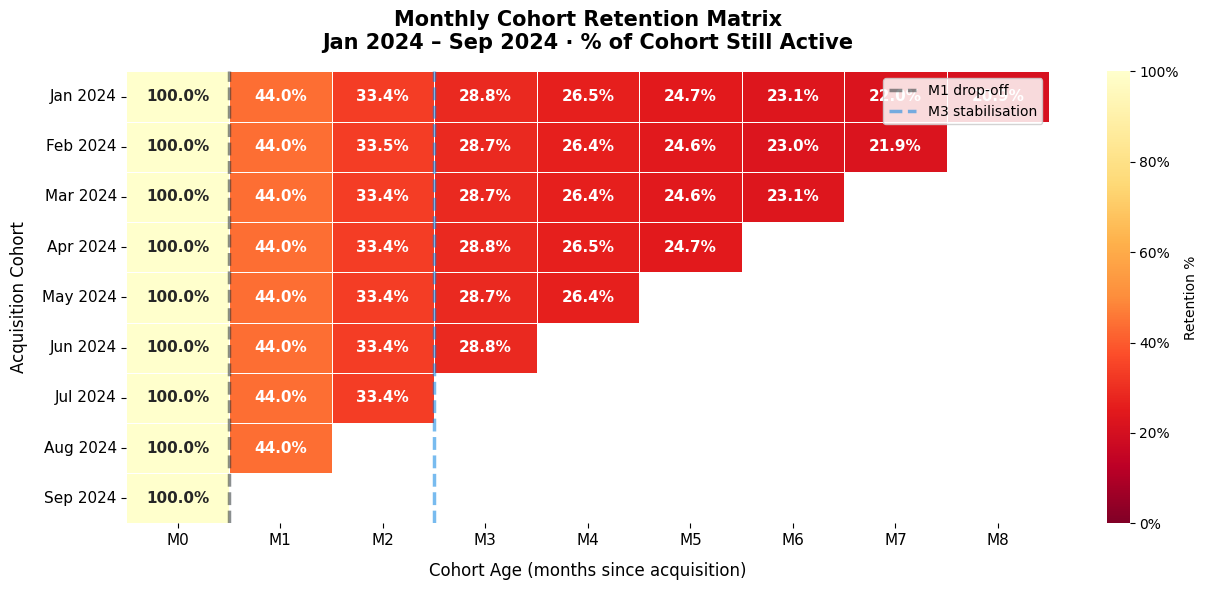

Saved → findings/cohort_retention_heatmap.png


In [6]:
retention_frac = retention / 100

row_labels = [p.strftime('%b %Y') for p in retention_frac.index.to_timestamp()]
col_labels = [f'M{i}' for i in retention_frac.columns]

fig, ax = plt.subplots(figsize=(13, 6))
mask = retention_frac.isna()

sns.heatmap(
    retention_frac,
    ax          = ax,
    mask        = mask,
    annot       = True,
    fmt         = '.1%',
    cmap        = 'YlOrRd_r',
    vmin        = 0,
    vmax        = 1,
    linewidths  = 0.6,
    linecolor   = 'white',
    cbar_kws    = {'label': 'Retention %', 'format': mtick.PercentFormatter(xmax=1)},
    xticklabels = col_labels,
    yticklabels = row_labels,
    annot_kws   = {'size': 11, 'weight': 'bold'},
)

ax.set_title(
    'Monthly Cohort Retention Matrix\nJan 2024 – Sep 2024 · % of Cohort Still Active',
    fontsize=15, fontweight='bold', pad=16
)
ax.set_xlabel('Cohort Age (months since acquisition)', fontsize=12, labelpad=10)
ax.set_ylabel('Acquisition Cohort', fontsize=12, labelpad=10)
ax.tick_params(axis='both', labelsize=11)

ax.axvline(x=1, color='#2d3436', linewidth=2.5, linestyle='--', alpha=0.55, label='M1 drop-off')
ax.axvline(x=3, color='#0984e3', linewidth=2.5, linestyle='--', alpha=0.55, label='M3 stabilisation')
ax.legend(loc='upper right', fontsize=10, framealpha=0.85)

plt.tight_layout()
fig.savefig('../findings/cohort_retention_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved → findings/cohort_retention_heatmap.png')

## 5 · Retention Curve Shape Analysis

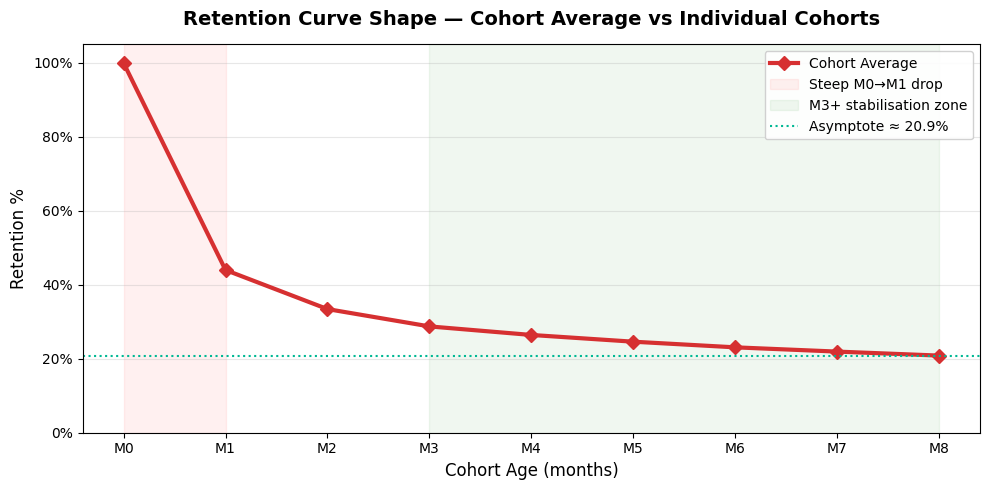

Saved → findings/retention_curve.png


In [7]:
avg_retention = retention.mean(axis=0).dropna()

fig2, ax2 = plt.subplots(figsize=(10, 5))

for cohort, row in retention.iterrows():
    row_clean = row.dropna()
    ax2.plot(row_clean.index, row_clean.values,
             marker='o', markersize=4, alpha=0.35, linewidth=1.2, color='#74b9ff')

ax2.plot(avg_retention.index, avg_retention.values,
         marker='D', markersize=7, linewidth=3, color='#d63031', label='Cohort Average')

ax2.axvspan(0, 1, alpha=0.06, color='red',   label='Steep M0→M1 drop')
ax2.axvspan(3, avg_retention.index.max(), alpha=0.06, color='green', label='M3+ stabilisation zone')
ax2.axhline(avg_retention.iloc[-1], color='#00b894', linewidth=1.5,
            linestyle=':', label=f'Asymptote ≈ {avg_retention.iloc[-1]:.1f}%')

ax2.set_title('Retention Curve Shape — Cohort Average vs Individual Cohorts',
              fontsize=14, fontweight='bold', pad=14)
ax2.set_xlabel('Cohort Age (months)', fontsize=12)
ax2.set_ylabel('Retention %', fontsize=12)
ax2.set_ylim(0, 105)
ax2.set_xticks(avg_retention.index)
ax2.set_xticklabels([f'M{i}' for i in avg_retention.index])
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.legend(fontsize=10, framealpha=0.9)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
fig2.savefig('../findings/retention_curve.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved → findings/retention_curve.png')

## 6 · Summary Statistics & Classification

In [8]:
print("=== Average Retention by Cohort Age ===")
for idx, val in avg_retention.items():
    print(f"  M{idx:1d}: {val:5.1f}%")

m1_drop          = avg_retention[0] - avg_retention[1]
m1_to_m3_further = avg_retention[1] - avg_retention[3]
asymptote        = avg_retention[avg_retention.index.max()]

print(f"\nM0→M1 absolute drop-off  : {m1_drop:.1f} pp")
print(f"M1→M3 further decay       : {m1_to_m3_further:.1f} pp  (deceleration in progress)")
print(f"Asymptotic retention (M8) : {asymptote:.1f}%")

if asymptote > 25:
    curve_type = "Flattening Bucket"
elif asymptote < 10:
    curve_type = "Leaky Bucket"
else:
    curve_type = "Mild Leaky Bucket (approaching flat)"

print(f"\nCurve Classification      : *** {curve_type} ***")

=== Average Retention by Cohort Age ===
  M0: 100.0%
  M1:  44.0%
  M2:  33.4%
  M3:  28.7%
  M4:  26.4%
  M5:  24.6%
  M6:  23.1%
  M7:  21.9%
  M8:  20.9%

M0→M1 absolute drop-off  : 56.0 pp
M1→M3 further decay       : 15.2 pp  (deceleration in progress)
Asymptotic retention (M8) : 20.9%

Curve Classification      : *** Mild Leaky Bucket (approaching flat) ***


In [9]:
retention.to_csv('../findings/cohort_retention_matrix.csv')
print('Saved → findings/cohort_retention_matrix.csv')
print('\nFull retention matrix (%):')
retention.round(2)

Saved → findings/cohort_retention_matrix.csv

Full retention matrix (%):


Cohort Index (months),0,1,2,3,4,5,6,7,8
Cohort Month,,,,,,,,,
2024-01,100.0000,44.0000,33.4300,28.7600,26.4800,24.6700,23.1400,22.0000,20.8600
2024-02,100.0000,44.0200,33.4800,28.7500,26.4300,24.5500,23.0400,21.8800,NaN
2024-03,100.0000,44.0000,33.4200,28.7500,26.4200,24.5800,23.0800,NaN,NaN
2024-04,100.0000,43.9700,33.4400,28.7800,26.4900,24.6600,NaN,NaN,NaN
2024-05,100.0000,43.9900,33.4100,28.7000,26.3800,NaN,NaN,NaN,NaN
2024-06,100.0000,44.0000,33.4500,28.7600,NaN,NaN,NaN,NaN,NaN
2024-07,100.0000,43.9900,33.4000,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,100.0000,44.0100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,100.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
